In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras.optimizers import Adam


In [2]:
IMG_PATH = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\images"
LBL_PATH = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\labels"

IMG_SIZE = 224

X = []
y = []

image_files = sorted(os.listdir(IMG_PATH))

for img_file in image_files:
    img = cv2.imread(os.path.join(IMG_PATH, img_file), cv2.IMREAD_GRAYSCALE)
    img = img / 255.0
    img = np.expand_dims(img, axis=-1)

    label_file = img_file.replace(".png", ".txt")
    with open(os.path.join(LBL_PATH, label_file)) as f:
        label = int(f.read().strip())

    X.append(img)
    y.append(label)

X = np.array(X)
y = np.array(y)

print("Images:", X.shape)
print("Labels:", y.shape)


Images: (6939, 224, 224, 1)
Labels: (6939,)


In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)


Train: (5551, 224, 224, 1)
Validation: (1388, 224, 224, 1)


In [4]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,1)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 222, 222, 32)      320       
                                                                 
 batch_normalization (BatchN  (None, 222, 222, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 111, 111, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 109, 109, 64)      18496     
                                                                 
 batch_normalization_1 (Batc  (None, 109, 109, 64)     256       
 hNormalization)                                                 
                                                        

In [5]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=16
)


Epoch 1/10
347/347 [==============================] - 431s 1s/step - loss: 0.5892 - accuracy: 0.7644 - val_loss: 0.6219 - val_accuracy: 0.5684
Epoch 2/10
347/347 [==============================] - 423s 1s/step - loss: 0.3950 - accuracy: 0.8040 - val_loss: 0.3525 - val_accuracy: 0.8329
Epoch 3/10
347/347 [==============================] - 422s 1s/step - loss: 0.3206 - accuracy: 0.8379 - val_loss: 0.2790 - val_accuracy: 0.8919
Epoch 4/10
347/347 [==============================] - 422s 1s/step - loss: 0.2460 - accuracy: 0.8824 - val_loss: 0.1952 - val_accuracy: 0.9200
Epoch 5/10
347/347 [==============================] - 418s 1s/step - loss: 0.1947 - accuracy: 0.9070 - val_loss: 0.1500 - val_accuracy: 0.9452
Epoch 6/10
347/347 [==============================] - 425s 1s/step - loss: 0.1687 - accuracy: 0.9270 - val_loss: 0.1288 - val_accuracy: 0.9467
Epoch 7/10
347/347 [==============================] - 430s 1s/step - loss: 0.1327 - accuracy: 0.9413 - val_loss: 0.3323 - val_accuracy: 0.8826

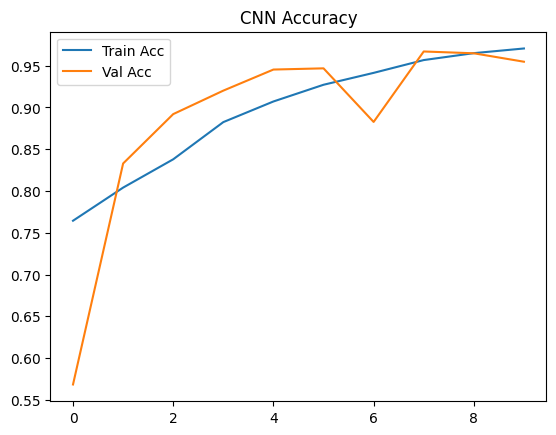

In [6]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title("CNN Accuracy")
plt.show()


              precision    recall  f1-score   support

           0       0.99      0.93      0.96       761
           1       0.92      0.98      0.95       627

    accuracy                           0.95      1388
   macro avg       0.95      0.96      0.95      1388
weighted avg       0.96      0.95      0.95      1388



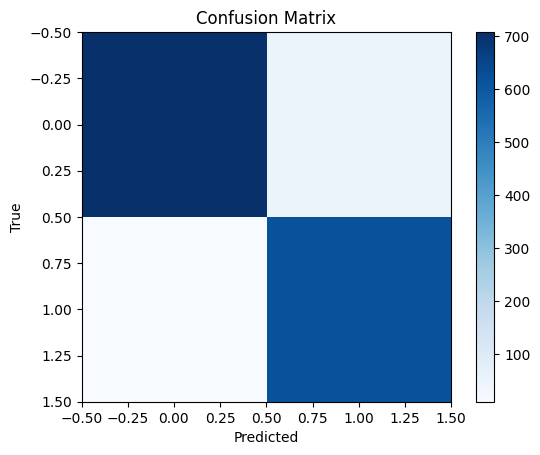

In [7]:
y_pred = (model.predict(X_val) > 0.5).astype(int)

print(classification_report(y_val, y_pred))

cm = confusion_matrix(y_val, y_pred)
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()
